In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models
     

In [8]:
df_train = pd.read_csv("../data/mnist_train.csv")
df_test = pd.read_csv("../data/mnist_test.csv")


In [11]:
df_test.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [12]:
X_train = df_train.drop("label", axis=1).values
y_train = df_train["label"].values

X_test = df_test.values

array([1, 0, 1, ..., 7, 6, 9], shape=(42000,))

In [14]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [15]:
X_train_img=X_train.reshape(-1,28,28)
X_test_img=X_test.reshape(-1,28,28)

In [19]:
Y_train_cat=to_categorical(y_train)


In [20]:
perceptron = Sequential(
    [
        Flatten(input_shape=(28, 28)),  # Flatten the input images to a 1D array
        Dense(10,activation='softmax')  # Output layer with 10 neurons for 10 classes
    ]
)

In [21]:
perceptron.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [23]:
history_preceptron = perceptron.fit(
    X_train_img,
    Y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.7778 - loss: 0.9570 - val_accuracy: 0.8542 - val_loss: 0.6022
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8673 - loss: 0.5347 - val_accuracy: 0.8782 - val_loss: 0.4809
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8810 - loss: 0.4587 - val_accuracy: 0.8852 - val_loss: 0.4318
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8874 - loss: 0.4211 - val_accuracy: 0.8932 - val_loss: 0.4035
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.8935 - loss: 0.3978 - val_accuracy: 0.8951 - val_loss: 0.3845


In [27]:
acc_precept = history_preceptron.history["val_accuracy"][-1]
print(acc_precept)

0.8951190710067749


In [32]:
ANN = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

ANN.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ann = ANN.fit(
    X_train_img,
    Y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9070 - loss: 0.3131 - val_accuracy: 0.9494 - val_loss: 0.1632
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9594 - loss: 0.1333 - val_accuracy: 0.9620 - val_loss: 0.1205
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9719 - loss: 0.0898 - val_accuracy: 0.9679 - val_loss: 0.1071
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9800 - loss: 0.0664 - val_accuracy: 0.9694 - val_loss: 0.1023
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9847 - loss: 0.0498 - val_accuracy: 0.9685 - val_loss: 0.1141


In [33]:
acc_ann= history_ann.history["val_accuracy"][-1]
print(acc_ann)

0.9684523940086365


In [34]:
X_train_cnn=X_train_img.reshape(-1, 28, 28, 1)
X_test_cnn=X_test_img.reshape(-1, 28, 28, 1)

In [35]:
CNN=Sequential(
    [
        Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')

    ]
)

In [36]:
CNN.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [37]:
history_cnn = CNN.fit(X_train_cnn, Y_train_cat, epochs=5, batch_size=32, validation_split=0.2)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 63s 51ms/step - accuracy: 0.9069 - loss: 0.3010 - val_accuracy: 0.9776 - val_loss: 0.0683
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 37s 35ms/step - accuracy: 0.9680 - loss: 0.1085 - val_accuracy: 0.9857 - val_loss: 0.0454
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 26s 25ms/step - accuracy: 0.9762 - loss: 0.0765 - val_accuracy: 0.9826 - val_loss: 0.0589
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 23s 22ms/step - accuracy: 0.9810 - loss: 0.0621 - val_accuracy: 0.9882 - val_loss: 0.0385
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 51s 48ms/step - accuracy: 0.9851 - loss: 0.0493 - val_accuracy: 0.9881 - val_loss: 0.0387


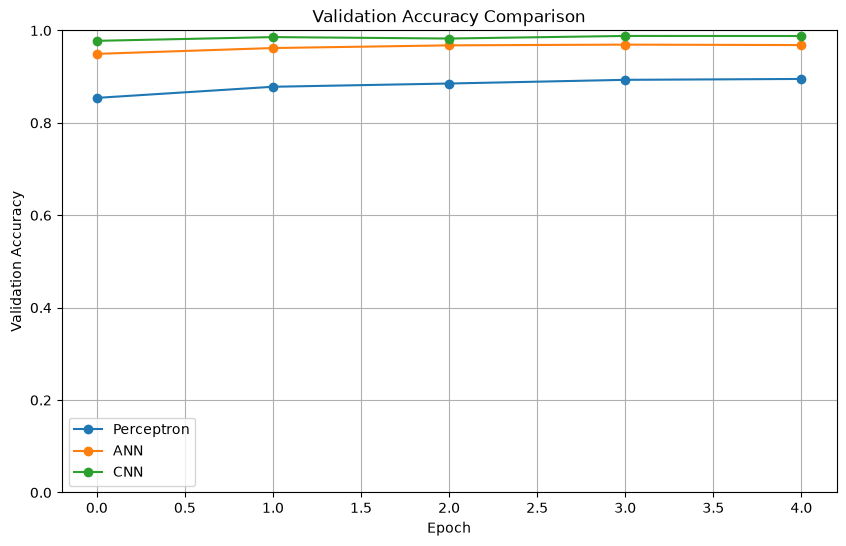

In [38]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_preceptron.history["val_accuracy"],
    marker="o",
    label="Perceptron"
)

plt.plot(
    history_ann.history["val_accuracy"],
    marker="o",
    label="ANN"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    marker="o",
    label="CNN"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

875/875 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step
875/875 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step
875/875 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step


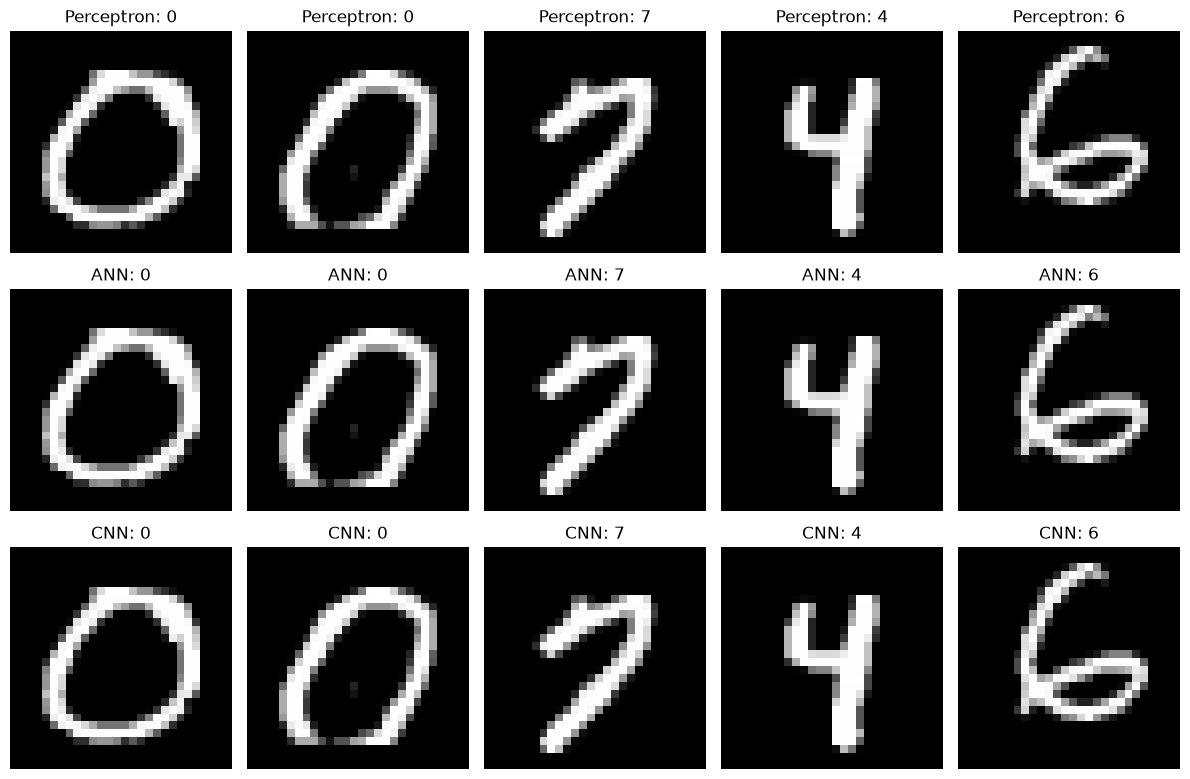

In [46]:
perceptron_labels = np.argmax(perceptron.predict(X_test_img), axis=1)
ann_labels = np.argmax(ANN.predict(X_test_img), axis=1)
cnn_labels = np.argmax(CNN.predict(X_test_cnn), axis=1)

random_indices = np.random.choice(
    len(X_test_img),
    size=5,
    replace=False
)

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

models = [
    ("Perceptron", perceptron_labels),
    ("ANN", ann_labels),
    ("CNN", cnn_labels)
]

for row, (model_name, labels) in enumerate(models):
    for column, image_index in enumerate(random_indices):
        axes[row, column].imshow(
            X_test_img[image_index],
            cmap="gray"
        )
        axes[row, column].set_title(
            f"{model_name}: {labels[image_index]}"
        )
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()